# Definir equipo grande vs equipo chico
Dentro de este archivo utilizaremos k-means para realizar un aprendizaje no supervisado, en el que obtendremos los resultado que más relaciona las variables que tiene más valor

In [140]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans



seasonGames = pd.read_csv('/Users/saulmartinezs/Documents/VS/epl_env/Dataset/equipos_por_temporada.csv')
teamData = pd.read_csv('/Users/saulmartinezs/Documents/VS/epl_env/Dataset/team_data.csv')
epl = pd.read_csv('/Users/saulmartinezs/Documents/VS/epl_env/Dataset/epl_final.csv')

Otro factor a tomar en cuenta es el domini en la primera parte.

In [141]:
epl['htWinHome'] = epl['HalfTimeResult'] == 'H'
epl['htDrawHome'] = epl['HalfTimeResult'] == 'D'
epl['htLoseHome'] = epl['HalfTimeResult'] == 'A'

epl['htWinAway'] = epl['HalfTimeResult'] == 'A'
epl['htDrawAway'] = epl['HalfTimeResult'] == 'D'
epl['htLoseAway'] = epl['HalfTimeResult'] == 'H'

ht_home = (
    epl.groupby(['Season', 'HomeTeam'], as_index=False)[['htWinHome', 'htDrawHome', 'htLoseHome']]
    .sum()
)
ht_away = (
    epl.groupby(['Season', 'AwayTeam'], as_index=False)[['htWinAway', 'htDrawAway', 'htLoseAway']]
    .sum()
)

ht_stats = ht_home.merge(
    ht_away,
    left_on=['Season', 'HomeTeam'],
    right_on=['Season', 'AwayTeam'],
    how='outer'
)

ht_stats['Team'] = ht_stats['HomeTeam'].fillna(ht_stats['AwayTeam'])

ht_stats['htTotalWins'] = ht_stats['htWinHome'].fillna(0) + ht_stats['htWinAway'].fillna(0)
ht_stats['htTotalDraws'] = ht_stats['htDrawHome'].fillna(0) + ht_stats['htDrawAway'].fillna(0)
ht_stats['htTotalLoses'] = ht_stats['htLoseHome'].fillna(0) + ht_stats['htLoseAway'].fillna(0)

cols_ht = ['Season', 'Team', 'htTotalWins', 'htTotalDraws', 'htTotalLoses']

seasonGames = seasonGames.merge(ht_stats[cols_ht], on=['Season', 'Team'], how='inner')
seasonGames['htWinsPercentage'] = seasonGames['htTotalWins'] / seasonGames['seasonGamesPlayed']
seasonGames['htDrawsPercentage'] = seasonGames['htTotalDraws'] / seasonGames['seasonGamesPlayed']
seasonGames['htLosesPercentage'] = seasonGames['htTotalLoses'] / seasonGames['seasonGamesPlayed']

home_stats = epl.groupby(['Season', 'HomeTeam'], as_index=False).agg(
    GoalsFor=('FullTimeHomeGoals', 'sum'),
    Shots=('HomeShots', 'sum'),
    ShotsOnTarget=('HomeShotsOnTarget', 'sum'),
    Fouls=('HomeFouls', 'sum'),
    YellowCards=('HomeYellowCards', 'sum'),
    RedCards=('HomeRedCards', 'sum')
).rename(columns={'HomeTeam': 'Team'})

away_stats = epl.groupby(['Season', 'AwayTeam'], as_index=False).agg(
    GoalsFor=('FullTimeAwayGoals', 'sum'),
    Shots=('AwayShots', 'sum'),
    ShotsOnTarget=('AwayShotsOnTarget', 'sum'),
    Fouls=('AwayFouls', 'sum'),
    YellowCards=('AwayYellowCards', 'sum'),
    RedCards=('AwayRedCards', 'sum')
).rename(columns={'AwayTeam': 'Team'})

teamData_season = (
    pd.concat([home_stats, away_stats], ignore_index=True)
    .groupby(['Season', 'Team'], as_index=False)
    .sum()
)

fTeam = pd.merge(seasonGames, teamData_season, on=['Season', 'Team'], how='inner')
print("Dimensiones de fTeam:", fTeam.shape)

fTeam['goalsPerGame'] = fTeam['GoalsFor'] / fTeam['seasonGamesPlayed']
fTeam['shotsPerGame'] = fTeam['Shots'] / fTeam['seasonGamesPlayed']
fTeam['shotAccuracy'] = fTeam['ShotsOnTarget'] / fTeam['Shots']
fTeam['conversionRate'] = fTeam['GoalsFor'] / fTeam['Shots']
fTeam['foulsPerGame'] = fTeam['Fouls'] / fTeam['seasonGamesPlayed']
fTeam['disciplineIndex'] = (fTeam['YellowCards'] + (fTeam['RedCards'] * 2)) / fTeam['seasonGamesPlayed']

Dimensiones de fTeam: (500, 31)


Mini Batch K means

In [143]:
kFrame = fTeam[[
    'wPercentage',
    'htWinsPercentage',
    'goalsPerGame',
    'shotsPerGame',
    'shotAccuracy',
    'conversionRate',
    'foulsPerGame',
    'disciplineIndex'
]]

xScaled = StandardScaler().fit_transform(kFrame)
x = pd.DataFrame(xScaled, columns=kFrame.columns, index=kFrame.index)

modelo = KMeans(n_clusters=2,random_state=42, n_init=10).fit(x)
fTeam['cluster'] = modelo.labels_

print("\n--- TOP EQUIPOS POR CLUSTER Y TEMPORADA ---")
print(
    fTeam[['Season', 'Team', 'wPercentage', 'goalsPerGame', 'shotAccuracy', 'cluster']]
    .sort_values(by=['cluster', 'wPercentage'], ascending=[True, False])
)


print('Promedio Clusters')
print(fTeam.groupby('cluster')[kFrame.columns].mean().round(3))


--- TOP EQUIPOS POR CLUSTER Y TEMPORADA ---
      Season        Team  wPercentage  goalsPerGame  shotAccuracy  cluster
88   2004/05     Everton     0.515152      1.212121      0.480597        0
103  2005/06   Blackburn     0.500000      1.342105      0.476562        0
309  2015/16  Man United     0.500000      1.289474      0.332558        0
30   2001/02       Leeds     0.473684      1.394737      0.500000        0
116  2005/06   Tottenham     0.473684      1.394737      0.569343        0
..       ...         ...          ...           ...           ...      ...
429  2021/22   Leicester     0.368421      1.631579      0.388506        1
478  2023/24    West Ham     0.368421      1.578947      0.333333        1
497  2024/25   Tottenham     0.314286      1.800000      0.375519        1
157  2007/08   Tottenham     0.289474      1.736842      0.584178        1
305  2015/16     Everton     0.289474      1.552632      0.355691        1

[500 rows x 6 columns]
Promedio Clusters
         wPer

# Prueba Elbow

<Figure size 500x500 with 0 Axes>

<Figure size 500x500 with 0 Axes>

<Figure size 500x500 with 0 Axes>

<Figure size 500x500 with 0 Axes>

<Figure size 500x500 with 0 Axes>

<Figure size 500x500 with 0 Axes>

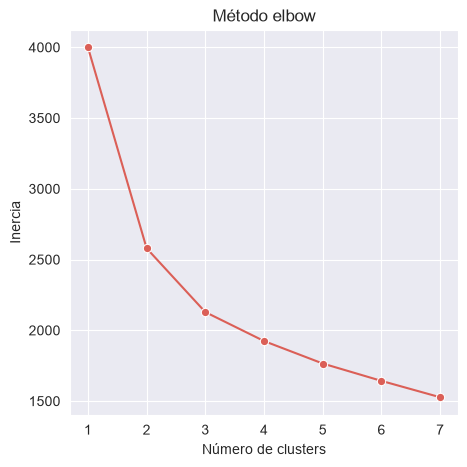

In [145]:
inercia = []

for i in range(1,8):
    modelo=KMeans(
        n_clusters= i,
        random_state=42,
        n_init=10
    )

    modelo.fit(x)
    inercia.append(modelo.inertia_)

    plt.figure(figsize=(5, 5))

sns.lineplot(
    x=range(1, 8),
    y=inercia,
    marker='o'
)

plt.title('Método elbow')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.xticks(range(1, 8))
plt.grid(True)

plt.show()




Tomaremos k=2 ya que para distinguir la grandeza y tener más precisión de un resultado inesperado a tomar en cuenta.

         wPercentage  htWinsPercentage  ...  foulsPerGame  disciplineIndex
cluster                                 ...                               
0              0.290             0.236  ...        11.877            1.831
1              0.561             0.421  ...        10.804            1.663

[2 rows x 8 columns]


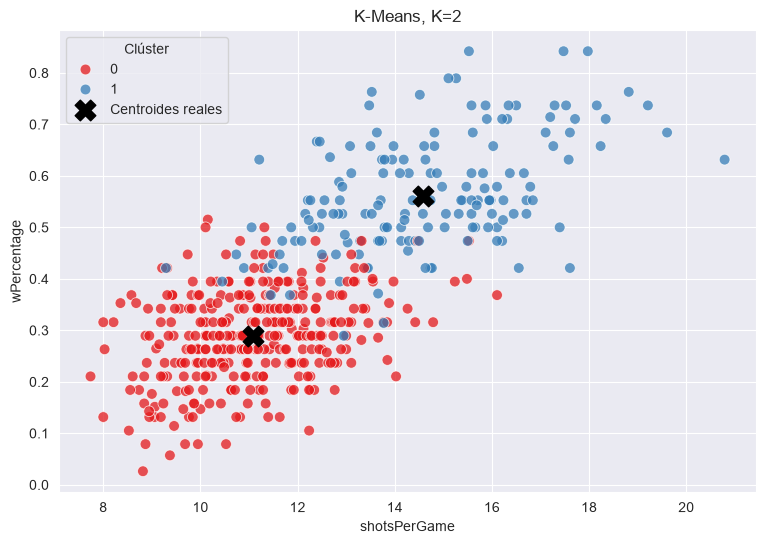

In [148]:
modelo = KMeans(n_clusters=2,random_state=42, n_init=10).fit(x)
fTeam['cluster'] = modelo.labels_

print(fTeam.groupby('cluster')[kFrame.columns].mean().round(3))

centroides = fTeam.groupby('cluster')[['shotsPerGame', 'wPercentage']].mean()

sns.set_style('darkgrid')
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=fTeam,
    x='shotsPerGame',
    y='wPercentage',
    hue='cluster',
    palette='Set1',
    alpha=0.75,
    s=60
)

plt.scatter(
    centroides['shotsPerGame'],
    centroides['wPercentage'],
    color='black',
    marker='X',
    s=220,
    label='Centroides reales'
)

plt.title('K-Means, K=2')
plt.xlabel('shotsPerGame')
plt.ylabel('wPercentage')
plt.legend(title='Clúster')
plt.show()

Clúster Azul: Agrupa las campañas más dominantes, con su centroide real ubicado alrededor de 14.5 disparos por partido y 55% de victorias

Clúster Rojo : Concentra las temporadas de media tabla y zona baja, con su centroide cerca de 11.0 disparos por partido y 28.5% de victorias.

# PCA 2


(500, 2)


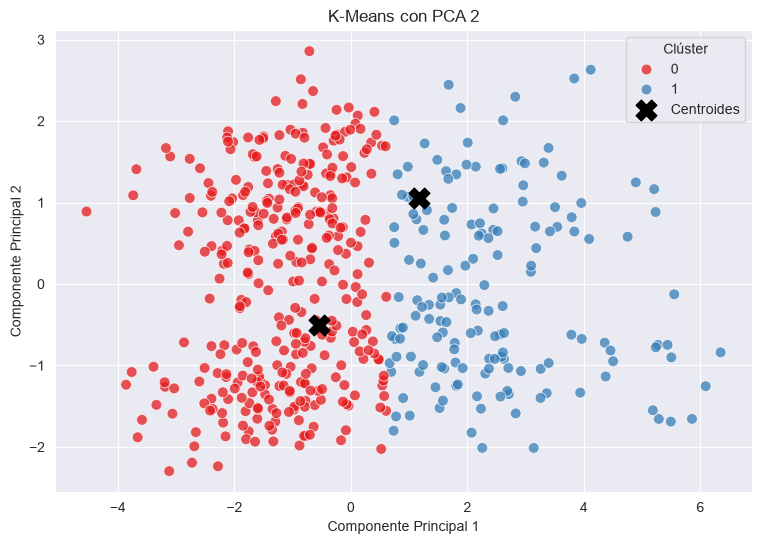

In [ ]:
pca = PCA(n_components=2)

x_pca = pca.fit_transform(x)

print(x_pca.shape)

sns.set_style('darkgrid')

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=x_pca[:, 0],
    y=x_pca[:, 1],
    hue=fTeam['cluster'],
    palette='Set1',
    alpha=0.75,
    s=60
)

plt.scatter(
    modelo.cluster_centers_[:, 0],
    modelo.cluster_centers_[:, 1],
    color='black',
    marker='X',
    s=220,
    label='Centroides'
)

plt.title('K-Means con PCA 2')
plt.xlabel('Comp. Principal 1')
plt.ylabel('Comp. Principal 2')
plt.legend(title='Clúster')
plt.show()

In [152]:
print(pca.explained_variance_ratio_)

print('Varianza acumulada:',pca.explained_variance_ratio_.sum() * 100,'%')

[0.50840972 0.18069358]
Varianza acumulada: 68.91033040449443 %


### Análisis de resultados mediante PCA y K-Means

1. **Separación en el Componente Principal 1 (Eje X):** Se puede observar una separación bastante marcada alrededor de PC1 ≈ 0.7, donde los equipos que se encuentran a la izquierda pertenecen al **Clúster 0 (rojo)** y los que están a la derecha al **Clúster 1 (azul)**. Esto nos indica que el primer componente principal está relacionado principalmente con el rendimiento de los equipos, considerando características como victorias, goles, disparos y efectividad.

2. **Variabilidad en el Componente Principal 2 (Eje Y):** En el eje vertical se pueden observar diferencias entre los equipos relacionadas con otras características, principalmente las faltas y la disciplina. Esto muestra que dentro de ambos grupos existen equipos con comportamientos diferentes en estos aspectos, pero que no afectan tanto la separación principal que realiza K-Means.

3. **Varianza explicada por PCA:** Al utilizar PCA con dos componentes principales, se obtuvo un 50.84 % de varianza para el primer componente y un 18.07 % para el segundo, dando un total acumulado de **68.91 %**. Esto quiere decir que estamos conservando aproximadamente el 69 % de la información de las características originales, mientras que el 31.09 % restante no se representa en la gráfica. Considero que es un resultado aceptable para poder visualizar los grupos en dos dimensiones, aunque existe cierta pérdida de información.

**Conclusión:** Con K-Means y PCA podemos observar que los equipos se distribuyen en dos grupos bastante diferenciados, lo que permite identificar una separación entre los equipos de élite y el resto de la liga. Aunque PCA reduce la información a dos componentes, la varianza acumulada del 68.91 % permite obtener una representación útil para analizar cómo se distribuyen los equipos y qué características pueden influir en su rendimiento.

In [153]:
fTeam.to_csv('/Users/saulmartinezs/Documents/VS/epl_env/Dataset/kMeans.csv', index=False)
